In [1]:
import pybaseball as pyb
import numpy as np
import matplotlib.pyplot as plt
from adjustText import adjust_text

In [2]:
df_babip = pyb.pitching_stats_bref(2025)
df_babip.head()

,Name,Age,#days,Lev,Tm,G,GS,W,L,SV,...,StL,StS,GB/FB,LD,PU,WHIP,BAbip,SO9,SO/W,mlbID
1,Andrew Abbott,26,365,Maj-NL,Cincinnati,29,29,10.0,7.0,NaN,...,0.16,0.11,0.33,0.24,0.11,1.148,0.276,8.1,3.47,671096
2,Mick Abel,23,365,"Maj-AL,Maj-NL","Minnesota,Philadelphia",10,8,3.0,4.0,NaN,...,0.15,0.11,0.37,0.25,0.04,1.513,0.318,9.0,2.44,690953
3,Philip Abner,23,364,Maj-NL,Arizona,5,0,NaN,NaN,NaN,...,0.17,0.11,0.30,0.10,0.30,2.182,0.500,12.3,1.67,691769
4,Bryan Abreu,28,366,Maj-AL,Houston,70,0,3.0,4.0,7.0,...,0.16,0.18,0.36,0.31,0.09,1.155,0.309,13.3,3.39,650556
5,Garrett Acton,27,378,Maj-AL,Tampa Bay,1,0,NaN,NaN,NaN,...,0.14,0.05,0.00,0.00,0.67,2.000,0.000,0.0,0.00,670183


In [3]:
filtered_df = df_babip[df_babip["IP"] > 100]
filtered_df

,Name,Age,#days,Lev,Tm,G,GS,W,L,SV,...,StL,StS,GB/FB,LD,PU,WHIP,BAbip,SO9,SO/W,mlbID
1,Andrew Abbott,26,365,Maj-NL,Cincinnati,29,29,10.0,7.0,NaN,...,0.16,0.11,0.33,0.24,0.11,1.148,0.276,8.1,3.47,671096
12,Sandy Alcantara,29,366,Maj-NL,Miami,31,31,11.0,12.0,NaN,...,0.16,0.09,0.47,0.25,0.05,1.271,0.278,7.3,2.49,645261
18,Logan Allen,26,364,Maj-AL,Cleveland,30,29,8.0,11.0,NaN,...,0.17,0.08,0.45,0.23,0.08,1.398,0.299,7.0,1.97,671106
29,Tyler Anderson,35,394,Maj-AL,Los Angeles,26,26,2.0,8.0,NaN,...,0.15,0.11,0.29,0.25,0.10,1.408,0.263,6.9,1.82,542881
49,Chris Bassitt,36,330,Maj-AL,Toronto,39,31,11.0,9.0,NaN,...,0.17,0.10,0.46,0.24,0.08,1.291,0.310,8.8,3.26,605135
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
864,Zack Wheeler,35,408,Maj-NL,Philadelphia,24,24,10.0,5.0,NaN,...,0.14,0.14,0.42,0.24,0.06,0.935,0.267,11.7,5.91,554430
873,Gavin Williams,25,362,Maj-AL,Cleveland,32,32,12.0,6.0,NaN,...,0.16,0.12,0.46,0.22,0.05,1.261,0.257,9.4,2.15,668909
887,Bryan Woo,25,342,Maj-AL,Seattle,32,30,15.0,7.0,NaN,...,0.14,0.12,0.42,0.23,0.09,0.942,0.241,9.4,5.13,693433
890,Simeon Woods Richardson,24,364,Maj-AL,Minnesota,23,22,7.0,4.0,NaN,...,0.15,0.10,0.33,0.21,0.11,1.275,0.265,8.6,2.33,680573


In [4]:
filtered_df.loc[filtered_df["IP"].round(1) % 1 == 0.1, "IP"] += 0.23
filtered_df.loc[filtered_df["IP"].round(1) % 1 == 0.2, "IP"] += 0.47

In [5]:
H_total = filtered_df["H"].sum()
AB_total = filtered_df["AB"].sum()
HR_total = filtered_df["HR"].sum()
SO_total = filtered_df["SO"].sum()
SF_total = filtered_df["SF"].sum()

total_babip = (H_total - HR_total) / (AB_total - SO_total -HR_total + SF_total)
total_babip.round(4)

np.float64(0.2859)

In [6]:
HR_total = filtered_df["HR"].sum()
BB_total = filtered_df["BB"].sum()
HBP_total = filtered_df["HBP"].sum()
SO_total = filtered_df["SO"].sum()
IP_total = filtered_df["IP"].sum()

total_fip = (13 * HR_total + 3 * (BB_total + HBP_total) - 2 * SO_total) / IP_total + 3.135
total_fip.round(4)

np.float64(4.0763)

In [7]:
table = filtered_df[["Name", "BAbip"]].copy()

table["babip difference"] = (
    table["BAbip"] - total_babip
    .round(3)
)

table["FIP"] = (
    (13 * filtered_df["HR"] + 3 * (filtered_df['BB'] + filtered_df['HBP']) - 2 * filtered_df['SO']) / filtered_df['IP'] + 3.135
)

table["FIP"] = table["FIP"].round(3)

table["babip-"] = (
    100 * table["BAbip"] / total_babip
)

table["babip-"] = table["babip-"].round()

table["FIP difference"] = (
    table["FIP"] - total_fip
    .round(3)
)

table["FIP-"] = (
    100 * table["FIP"] / total_fip
)

table["FIP-"] = table["FIP-"].round()

table

,Name,BAbip,babip difference,FIP,babip-,FIP difference,FIP-
1,Andrew Abbott,0.276,-0.010,3.659,97.0,-0.417,90.0
12,Sandy Alcantara,0.278,-0.008,4.283,97.0,0.207,105.0
18,Logan Allen,0.299,0.013,4.377,105.0,0.301,107.0
29,Tyler Anderson,0.263,-0.023,5.604,92.0,1.528,137.0
49,Chris Bassitt,0.310,0.024,3.889,108.0,-0.187,95.0
...,...,...,...,...,...,...,...
864,Zack Wheeler,0.267,-0.019,3.001,93.0,-1.075,74.0
873,Gavin Williams,0.257,-0.029,4.278,90.0,0.202,105.0
887,Bryan Woo,0.241,-0.045,3.501,84.0,-0.575,86.0
890,Simeon Woods Richardson,0.265,-0.021,4.521,93.0,0.445,111.0


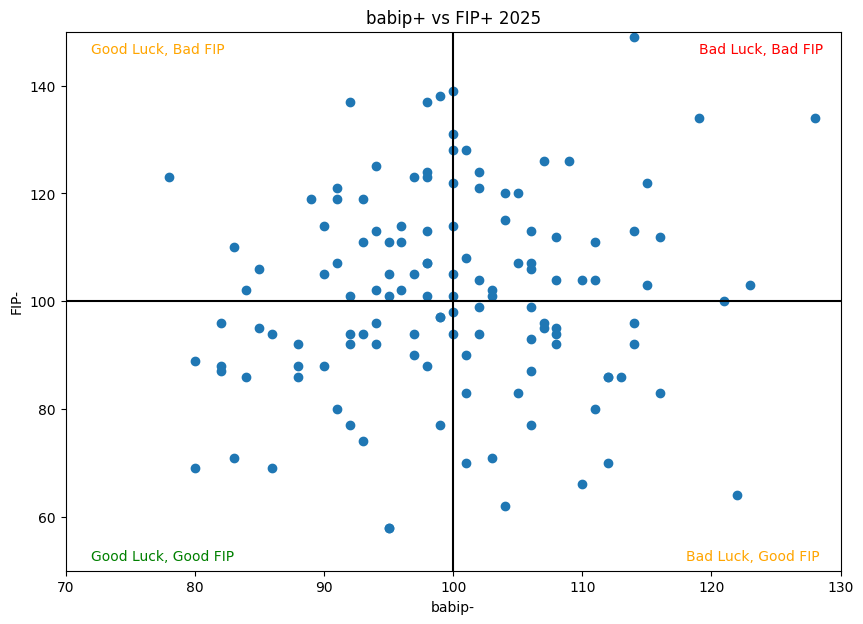

In [8]:
plt.figure(figsize=(10, 7))

plt.scatter(
    table["babip-"],
    table["FIP-"]
)

plt.xlabel("babip-")
plt.ylabel("FIP-")
plt.title("babip+ vs FIP+ 2025")

plt.xlim(70, 130)
plt.ylim(50, 150)

plt.plot([70, 130], [100, 100], color="black")
plt.plot([100, 100], [50, 150], color="black")

plt.text(72, 52, "Good Luck, Good FIP", color = 'green')
plt.text(72, 146, "Good Luck, Bad FIP", color = 'orange')
plt.text(118, 52, "Bad Luck, Good FIP", color = 'orange')
plt.text(119, 146, "Bad Luck, Bad FIP", color = 'red')

plt.show()

In [17]:
filtered_table = table[["Name", "babip-", "FIP-"]].copy()

filtered_table["Rank"] = (
    (table["FIP-"] - 100) * -2 + (table["babip-"] - 100) * -1
)

filtered_table = filtered_table.sort_values("Rank", ascending = False)

filtered_table["Name"] = filtered_table["Name"].replace(
    "Cristopher S\\xc3\\xa1nchez",
    "Christopher Sanchez"
)

filtered_table["Name"] = filtered_table["Name"].replace(
    r"Jes\xc3\xbas Luzardo",
    "Jesus Luzardo"
)

filtered_table.head(15)

,Name,babip-,FIP-,Rank
747,Paul Skenes,95.0,58.0,89.0
748,Tarik Skubal,95.0,58.0,89.0
684,Trevor Rogers,80.0,69.0,82.0
219,Nathan Eovaldi,86.0,69.0,76.0
893,Yoshinobu Yamamoto,83.0,71.0,75.0
705,Christopher Sanchez,104.0,62.0,72.0
864,Zack Wheeler,93.0,74.0,59.0
167,Garrett Crochet,101.0,70.0,59.0
703,Chris Sale,110.0,66.0,58.0
108,Kris Bubic,103.0,71.0,55.0


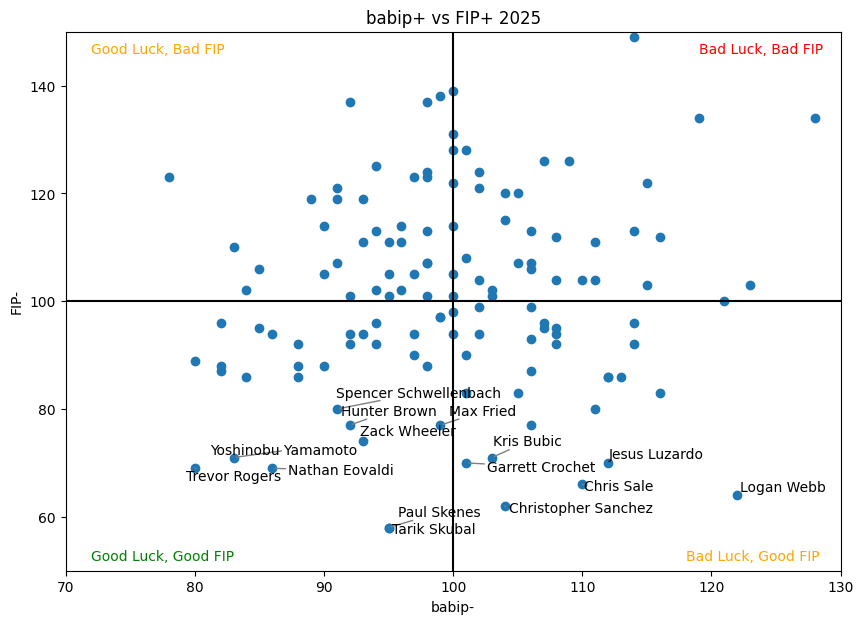

In [18]:
plt.figure(figsize=(10, 7))

plt.scatter(
    table["babip-"],
    table["FIP-"]
)

plt.xlabel("babip-")
plt.ylabel("FIP-")
plt.title("babip+ vs FIP+ 2025")

plt.xlim(70, 130)
plt.ylim(50, 150)

plt.plot([70, 130], [100, 100], color="black")
plt.plot([100, 100], [50, 150], color="black")

plt.text(72, 52, "Good Luck, Good FIP", color = 'green')
plt.text(72, 146, "Good Luck, Bad FIP", color = 'orange')
plt.text(118, 52, "Bad Luck, Good FIP", color = 'orange')
plt.text(119, 146, "Bad Luck, Bad FIP", color = 'red')

texts = []

for _, row in filtered_table.head(15).iterrows():
    texts.append(
        plt.text(
            row["babip-"],
            row["FIP-"],
            row["Name"]
        )
    )

adjust_text(
    texts,
    arrowprops=dict(arrowstyle="-", color="gray")
)

plt.show()

# Test

In [17]:
filtered_df.columns.tolist()
filtered_df["SO"].count()

np.int64(129)